<a href="https://colab.research.google.com/github/Nihat0311/Deep-Learning/blob/main/PyTorch2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn

In [ ]:
if torch.cuda.is_available():
  device="cuda"
elif torch.backends.mps.is_available():
  device="mps"
else:
  device="cpu"

In [ ]:
import torchvision
import torchvision.transforms.v2 as T

In [ ]:
toTensor=T.Compose([  # PIL
    T.ToImage(),
    T.ToDtype(torch.float32,scale=True),
])

In [ ]:
train_and_valid_data=torchvision.datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=toTensor
)

test_data=torchvision.datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=toTensor
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.22MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.7MB/s]


In [ ]:
train_data , valid_data=torch.utils.data.random_split(
    train_and_valid_data,
    [55_000,5_000]
)

In [ ]:
train_data[0]

(Image([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.1608, 0.5529, 0.0863, 0.1686, 0.1765, 0.0627, 0.1451, 0.4353,
          0.1451, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0784, 0.3608,
          0.5451, 0.5373, 0.5725, 0.5882, 0.6902, 0.6431, 0.4235, 0.4745, 0.7412,
          0.7804, 0.7255, 0.4980, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0627, 0.4902, 0.5059,
          0.3922, 0.3294, 0.3059, 0.2706, 0.3059, 0.2706, 0.5882, 0.5451, 0.6667,
          0.6588, 0.6667, 0.7333, 0.8196, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3922, 0.3451, 0.2980,
          0.3686, 0.3373, 0.3294, 0.3451, 0.3451, 0.3451, 0.7804, 0.4431, 0.6510,
          0.6980, 0.6824, 0.6980, 0.7725,

In [ ]:
X_sample,y_sample=train_data[0]

In [ ]:
y_sample

3

In [ ]:
X_sample.shape

torch.Size([1, 28, 28])

In [ ]:
X_sample.dtype

torch.float32

In [ ]:
train_and_valid_data.classes

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
train_and_valid_data.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

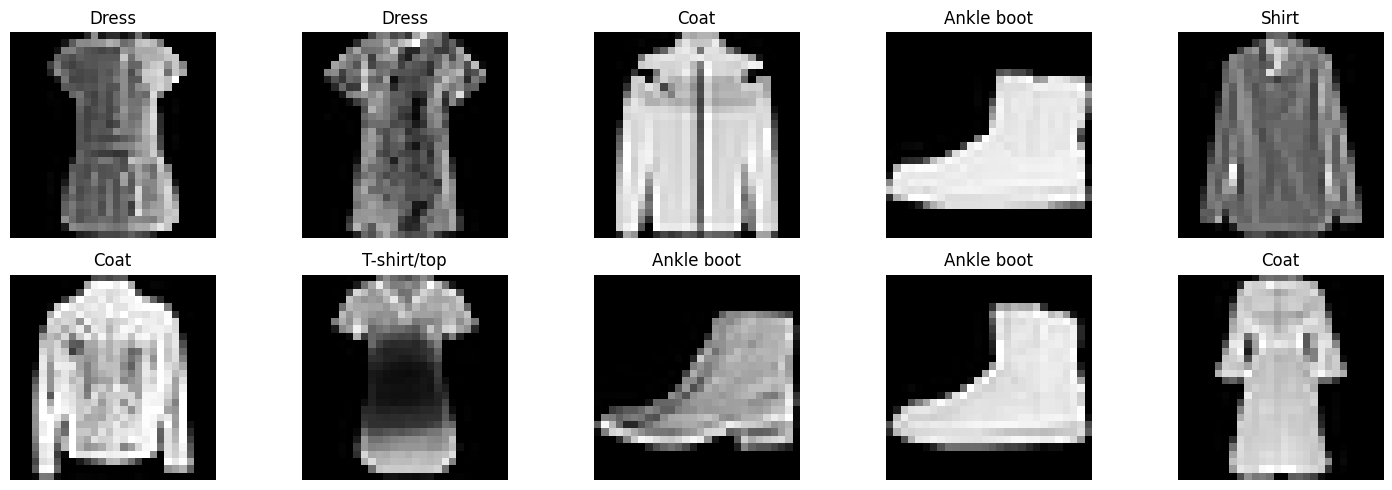

In [ ]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,5,figsize=(15,5))

for i ,ax in enumerate(axes.flat):
  X,y=train_data[i]
  ax.imshow(X.squeeze(),cmap="gray")
  ax.set_title(train_and_valid_data.classes[y])
  ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
class ImageClassifier(nn.Module):
  def __init__(self,n_inputs,n_hidden1,n_hidden2,n_classes):
    super().__init__()
    self.mlp=nn.Sequential(
        nn.Flatten(),
        nn.Linear(n_inputs,n_hidden1),
        nn.ReLU(),
        nn.Linear(n_hidden1,n_hidden2),
        nn.ReLU(),
        nn.Linear(n_hidden2,n_classes)
    )
  def forward(self,X):
    return self.mlp(X)


In [ ]:
torch.manual_seed(42)
model=ImageClassifier(
    n_inputs=1*28*28,
    n_hidden1=300,
    n_hidden2=200,
    n_classes=10
)

model=model.to(device)

In [ ]:
optimizer=torch.optim.SGD(model.parameters(),lr=0.01)
criterion=nn.CrossEntropyLoss() # binary olsaydi BinaryCrossEntropyLoss islederdik BCELoss

In [ ]:
from torch.utils.data import DataLoader

In [ ]:
train_loader=DataLoader(
    train_data,
    shuffle=True,
    batch_size=32
)
valid_loader=DataLoader(
    valid_data,
    shuffle=False,
    batch_size=32
)

test_loader=DataLoader(
    test_data,
    shuffle=False,
    batch_size=32
)

In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 59.7 MB/s eta 0:00:00


In [ ]:
import torchmetrics

In [ ]:
accuracy=torchmetrics.Accuracy(
    task='multiclass',
    num_classes=10
).to(device)

In [ ]:
n_epochs=20
model.train()
for epoch in range(n_epochs):
  total_loss=0
  for X_batch,y_batch in train_loader:
    X_batch,y_batch=X_batch.to(device),y_batch.to(device)

    y_logits=model(X_batch)
    loss=criterion(y_logits,y_batch)
    total_loss+=loss.item()

    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

  mean_loss=total_loss / len(train_loader)
  model.eval()
  accuracy.reset()
  with torch.no_grad():
    for X_batch,y_batch in valid_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)

      y_logits=model(X_batch)
      accuracy.update(y_logits,y_batch)
    val_accuracy=accuracy.compute()
    print(f"epoch{epoch+1}/{n_epochs}. train_loss:{mean_loss:.4}, val_accuracy:{val_accuracy:.4}")

epoch1/20. train_loss:1.091, val_accuracy:0.7652
epoch2/20. train_loss:0.5863, val_accuracy:0.8128
epoch3/20. train_loss:0.5073, val_accuracy:0.836
epoch4/20. train_loss:0.4678, val_accuracy:0.8478
epoch5/20. train_loss:0.4439, val_accuracy:0.8498
epoch6/20. train_loss:0.4256, val_accuracy:0.855
epoch7/20. train_loss:0.4107, val_accuracy:0.8606
epoch8/20. train_loss:0.3967, val_accuracy:0.8596
epoch9/20. train_loss:0.386, val_accuracy:0.8682
epoch10/20. train_loss:0.3759, val_accuracy:0.871
epoch11/20. train_loss:0.3661, val_accuracy:0.8706
epoch12/20. train_loss:0.3569, val_accuracy:0.874
epoch13/20. train_loss:0.3492, val_accuracy:0.871
epoch14/20. train_loss:0.3412, val_accuracy:0.871
epoch15/20. train_loss:0.3338, val_accuracy:0.8774
epoch16/20. train_loss:0.3277, val_accuracy:0.8818
epoch17/20. train_loss:0.3219, val_accuracy:0.8834
epoch18/20. train_loss:0.3152, val_accuracy:0.8728
epoch19/20. train_loss:0.3097, val_accuracy:0.8862
epoch20/20. train_loss:0.3043, val_accuracy:0.88

In [ ]:
import torch.nn.functional as F

In [ ]:
model.eval()
X_new,y_new=next(iter(test_loader))
X_new,y_new=X_new[:3].to(device),y_new[:3].to(device)
with torch.no_grad():
  y_logits=model(X_new)
  probas=F.softmax(y_logits,dim=1)
  preds=probas.argmax(dim=1)


In [ ]:
y_logits

tensor([[ -2.6609,  -6.1685,  -1.9423,  -1.7886,  -3.6101,   5.7385,  -2.3293,
           4.7112,   2.0605,   7.6469],
        [  3.7712,  -3.0676,  15.4047,   0.8481,   9.4049,  -8.4317,   8.7966,
         -14.2172,   1.7175, -13.6765],
        [  3.8497,  15.1028,   0.7057,   2.8584,   3.5640,  -7.5152,  -2.6786,
          -5.0615,  -0.8004, -10.6638]], device='cuda:0')

In [ ]:
probas

tensor([[2.7687e-05, 8.2975e-07, 5.6797e-05, 6.6233e-05, 1.0716e-05, 1.2305e-01,
         3.8573e-05, 4.4048e-02, 3.1099e-03, 8.2960e-01],
        [8.8303e-06, 9.4611e-09, 9.9618e-01, 4.7477e-07, 2.4699e-03, 4.4292e-11,
         1.3442e-03, 1.3606e-13, 1.1325e-06, 2.3362e-13],
        [1.2967e-05, 9.9997e-01, 5.5898e-07, 4.8121e-06, 9.7448e-06, 1.5035e-10,
         1.8952e-08, 1.7489e-09, 1.2397e-07, 6.4520e-12]], device='cuda:0')

In [ ]:
preds

tensor([9, 2, 1], device='cuda:0')

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 31.4 MB/s eta 0:00:00


In [ ]:
import optuna

In [ ]:
def objective(trial):
  learning_rate=trial.suggest_float('learning_rate',1e-5,1e-1,log=True)
  n_hidden=trial.suggest_int('n_hidden',100,1000)
  model=ImageClassifier(
      n_inputs=1*28*28,
      n_hidden1=n_hidden,
      n_hidden2=n_hidden,
      n_classes=10
  ).to(device)
  optimizer=torch.optim.SGD(model.parameters(),lr=learning_rate)
  criterion=nn.CrossEntropyLoss()
  n_epochs=10
  for epoch in range(n_epochs):
    model.train()
    for X_batch,y_batch in train_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      loss=criterion(logits,y_batch)
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
  model.eval()
  accuracy.reset()
  with torch.no_grad():
    for X_batch,y_batch in valid_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      accuracy.update(logits,y_batch)
    validation_accuracy=accuracy.compute().item()
  return validation_accuracy

In [ ]:
torch.manual_seed(42)
sample=optuna.samplers.TPESampler(seed=42)
study=optuna.create_study(direction='maximize',sampler=sample)
study.optimize(objective,n_trials=2)

[I 2026-04-03 15:49:42,892] A new study created in memory with name: no-name-0c5608e7-d2e2-41eb-83a3-8ba5589a6bd9
[I 2026-04-03 15:52:10,561] Trial 0 finished with value: 0.6836000084877014 and parameters: {'learning_rate': 0.00031489116479568613, 'n_hidden': 956}. Best is trial 0 with value: 0.6836000084877014.
[I 2026-04-03 15:54:36,759] Trial 1 finished with value: 0.8704000115394592 and parameters: {'learning_rate': 0.008471801418819975, 'n_hidden': 639}. Best is trial 1 with value: 0.8704000115394592.


In [ ]:
def objective(trial,train_loader,valid_loader):
  learning_rate=trial.suggest_float('learning_rate',1e-5,1e-1,log=True)
  n_hidden=trial.suggest_int('n_hidden',100,1000)
  model=ImageClassifier(
      n_inputs=1*28*28,
      n_hidden1=n_hidden,
      n_hidden2=n_hidden,
      n_classes=10
  ).to(device)
  optimizer=torch.optim.SGD(model.parameters(),lr=learning_rate)
  criterion=nn.CrossEntropyLoss()
  n_epochs=10
  for epoch in range(n_epochs):
    model.train()
    for X_batch,y_batch in train_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      loss=criterion(logits,y_batch)
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
  model.eval()
  accuracy.reset()
  with torch.no_grad():
    for X_batch,y_batch in valid_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      accuracy.update(logits,y_batch)
    validation_accuracy=accuracy.compute().item()
  return validation_accuracy
objective_with_data=lambda trial:objective(trial,train_loader=train_loader,valid_loader=valid_loader)
study.optimize(objective_with_data,n_trials=1)

[I 2026-04-03 15:59:28,369] Trial 2 finished with value: 0.4251999855041504 and parameters: {'learning_rate': 4.207988669606632e-05, 'n_hidden': 240}. Best is trial 1 with value: 0.8704000115394592.


In [ ]:
from functools import partial

objective_with_data=partial(objective,train_loader=train_loader,valid_loader=valid_loader)
study.optimize(objective_with_data,n_trials=1)

In [ ]:
pruner=optuna.pruners.MedianPruner(
    n_startup_trials=5,
    n_warmup_steps=0,
    interval_steps=1
)

study=optuna.create_study(
    direction='maximize',
    sampler=sample,
    pruner=pruner
)

[I 2026-04-03 16:13:59,885] A new study created in memory with name: no-name-4a94f2fc-5403-433a-b627-9d1e6af7f529


In [ ]:
def objective(trial,train_loader,valid_loader):
  learning_rate=trial.suggest_float('learning_rate',1e-5,1e-1,log=True)
  n_hidden=trial.suggest_int('n_hidden',100,1000)
  model=ImageClassifier(
      n_inputs=1*28*28,
      n_hidden1=n_hidden,
      n_hidden2=n_hidden,
      n_classes=10
  ).to(device)
  optimizer=torch.optim.SGD(model.parameters(),lr=learning_rate)
  criterion=nn.CrossEntropyLoss()
  n_epochs=10
  for epoch in range(n_epochs):
    model.train()
    for X_batch,y_batch in train_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      loss=criterion(logits,y_batch)
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
  model.eval()
  accuracy.reset()
  with torch.no_grad():
    for X_batch,y_batch in valid_loader:
      X_batch,y_batch=X_batch.to(device),y_batch.to(device)
      logits=model(X_batch)
      accuracy.update(logits,y_batch)
    validation_accuracy=accuracy.compute().item()
    trial.report(validation_accuracy,epoch)
    if trial.should_prune():
      raise optuna.TrialPruned()
  return validation_accuracy

study.optimize(objective_with_data_partial,n_trials=1)

In [ ]:
torch.save(model,'my_fashion_mist.pt')

In [ ]:
loaded_model=torch.load('my_fashion_mist.pt',weights_only=False)

In [ ]:
loaded_model.eval()
y_pred_logits=loaded_model(X_new)

In [ ]:
new_model=ImageClassifier(
    n_inputs=1*28*28,
    n_hidden1=300,
    n_hidden2=200,
    n_classes=10
)
torch.save(model.state_dict(),'my_fashion_mist_weights.pt')

In [ ]:
loaded_weights=torch.load('my_fashion_mist_weights.pt',weights_only=True)
new_model.load_state_dict(loaded_weights)
new_model.eval()

ImageClassifier(
  (mlp): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=300, bias=True)
    (2): ReLU()
    (3): Linear(in_features=300, out_features=200, bias=True)
    (4): ReLU()
    (5): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
model_data={
    'model_state_dict':model.state_dict(),
    'model_hyperparameters':{
        'n_inputs':1*28*28,
        'n_hidden1':300,
        'n_hidden2':200,
        'n_classes':10
    }
}
torch.save(model_data,'my_fashion_mnist_model.pt')

In [ ]:
loaded_data=torch.load('my_fashion_mnist_model.pt',weights_only=True)
new_model=ImageClassifier(**loaded_data['model_hyperparameters'])
new_model.load_state_dict(loaded_data['model_state_dict'])
new_model.eval()

ImageClassifier(
  (mlp): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=300, bias=True)
    (2): ReLU()
    (3): Linear(in_features=300, out_features=200, bias=True)
    (4): ReLU()
    (5): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
checkpoint={
    'epoch':epoch,
    'model_state_dict':model.state_dict(),
    'optimizer_state_dict':optimizer.state_dict()
}
torch.save(checkpoint,'my_fashion_mnist_checkpoint.pt')

In [ ]:
new_model=ImageClassifier(
    n_inputs=1*28*28,
    n_hidden1=300,
    n_hidden2=200,
    n_classes=10
).to(device)


In [ ]:
new_model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [ ]:
new_optimizer=torch.optim.SGD(new_model.parameters(),lr=0.01)


In [ ]:
new_optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

In [ ]:
start_epoch=checkpoint['epoch']
print(start_epoch)

19


In [ ]:
new_model.train()

ImageClassifier(
  (mlp): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=300, bias=True)
    (2): ReLU()
    (3): Linear(in_features=300, out_features=200, bias=True)
    (4): ReLU()
    (5): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
for epoch in range(start_epoch+1,27):
  new_model.train()
  for X_batch,y_batch in train_loader:
    X_batch,y_batch=X_batch.to(device),y_batch.to(device)

    new_optimizer.zero_grad()
    logits=new_model(X_batch)
    loss=criterion(logits,y_batch)
    loss.backward()
    new_optimizer.step()

In [ ]:
torchscript_model=torch.jit.trace(model,X_new)

In [ ]:
torchscript_model=torch.jit.script(model)

In [ ]:
optimized_model=torch.jit.optimize_for_inference(torchscript_model)

In [ ]:
torchscript_model.save('my_fashion_torchscript.pt')

In [ ]:
loaded_torchscript_model=torch.jit.load('my_fashion_torchscript.pt')